# Instance Segmentation: DBSCAN и U-Net

**ФИО студента:** Гришин Никита Андреевич

## Описание задания

**Цель работы:** реализовать два подхода к сегментации экземпляров объектов — на основе кластеризации DBSCAN и на основе нейронной сети U-Net, и сравнить их по метрикам качества

Важно, что нужна именно *instance*-сегментация: каждый объект должен получить свою отдельную маску, даже если все объекты одного класса

**Задачи:**
1. Выбрать открытый датасет для Instance Segmentation, описать его и подготовить данные.
2. Реализовать выделение экземпляров с помощью DBSCAN (кластеризация пикселей по признакам).
3. Реализовать U-Net, которая предсказывает маску объектов и их границы, и с помощью постобработки разделить объекты на экземпляры.
4. Посчитать метрики Instance Segmentation на одной и той же тестовой выборке.
5. Сравнить методы, разобрать типичные ошибки и сделать выводы.

## Датасет

Взял датасет **BBBC038** (он же *2018 Data Science Bowl*, stage1_train) — изображения клеточных ядер под микроскопом

- Ссылка: https://bbbc.broadinstitute.org/BBBC038 (также https://www.kaggle.com/c/data-science-bowl-2018)
- Прямая ссылка на архив: https://data.broadinstitute.org/bbbc/BBBC038/stage1_train.zip

Что внутри:
- 670 изображений разного размера
- для каждого изображения есть папка `masks/`, в которой каждое ядро лежит отдельной бинарной маской, как раз разметка экземпляров
- изображения разных типов: в основном флуоресцентная микроскопия (светлые ядра на тёмном фоне), но есть и снимки в светлом поле

Выбрал этот датасет так как объекты одного класса, их много на картинке, они часто соприкасаются — хорошо видно, умеет ли метод разделять отдельные экземпляры

### Импорты

In [1]:
import os
import glob
import random
import time
import zipfile
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

from skimage import io, transform, color
from skimage.filters import threshold_otsu
from skimage.measure import label
from skimage.segmentation import find_boundaries, watershed, expand_labels
from scipy import ndimage as ndi
from sklearn.cluster import DBSCAN

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

Устройство: cuda


### Скачивание датасета

In [2]:
DATA_URL = "https://data.broadinstitute.org/bbbc/BBBC038/stage1_train.zip"
DATA_DIR = "./data"
ZIP_PATH = os.path.join(DATA_DIR, "stage1_train.zip")
IMG_DIR = os.path.join(DATA_DIR, "stage1_train")

os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(ZIP_PATH):
    print("Скачиваю датасет...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

if not os.path.exists(IMG_DIR):
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(IMG_DIR)

ids = sorted(os.listdir(IMG_DIR))
print("Всего изображений:", len(ids))

Всего изображений: 670


### Загрузка и предобработка

Что делаю с каждым изображением:
1. Читаю картинку, убираю альфа-канал. PNG-файлы в датасете хранятся с 4 каналами: R, G, B и A (прозрачность). Прозрачность нам не нужна, поэтому беру только первые три канала
2. Перевожу в оттенки серого. Вместо трёх каналов остаётся один, яркость от 0 до 1 потому что у ядер почти нет полезной цветовой информации, главное — яркость
3. Если фон светлый (средняя яркость > 0.5), инвертирую картинку — тогда у всех изображений ядра светлые на тёмном фоне
3. Все отдельные маски ядер собираю в одну карту экземпляров: фон = 0, первое ядро = 1, второе = 2 и т.д.
4. Привожу всё к размеру 256×256

In [ ]:
IMG_SIZE = 256

def load_sample(sample_id):
    folder = os.path.join(IMG_DIR, sample_id)
    img = io.imread(os.path.join(folder, "images", sample_id + ".png"))[:, :, :3]
    gray = color.rgb2gray(img)  # перевожу в оттенки серого

    # светлый фон инвертирую
    is_bright = gray.mean() > 0.5
    if is_bright:
        gray = 1.0 - gray

    # собираю карту экземпляров
    inst = np.zeros(gray.shape, dtype=np.int32)
    mask_files = sorted(glob.glob(os.path.join(folder, "masks", "*.png")))
    for k, mf in enumerate(mask_files, start=1):
        m = io.imread(mf) > 0
        inst[m] = k

    # ресайз
    gray_r = transform.resize(gray, (IMG_SIZE, IMG_SIZE), anti_aliasing=True).astype(np.float32)
    inst_r = transform.resize(inst, (IMG_SIZE, IMG_SIZE), order=0, preserve_range=True,
                              anti_aliasing=False).astype(np.int32)
    # после ресайза совсем маленькие объекты могли пропасть, перенумеруем id подряд
    inst_r = relabel(inst_r)
    return img, gray_r, inst_r, is_bright


def remove_small(arr, min_size):
    # удаляю объекты меньше min_size пикселей
    inst = label(arr, connectivity=1) if arr.dtype == bool else arr.copy()
    sizes = np.bincount(inst.ravel())
    small = sizes < min_size
    small[0] = False
    inst[small[inst]] = 0
    return inst > 0 if arr.dtype == bool else inst


def relabel(inst):
    # перенумеровываем id объектов подряд
    _, new = np.unique(inst, return_inverse=True)
    new = new.reshape(inst.shape).astype(np.int32)
    if inst.min() > 0:  # если фона нет вообще, нумерация должна начинаться с 1
        new += 1
    return new


t0 = time.time()
images_orig, images, labels, bright = [], [], [], []
for sid in ids:
    img, g, lab, b = load_sample(sid)
    images_orig.append(img)
    images.append(g)
    labels.append(lab)
    bright.append(b)
images = np.stack(images)
labels = np.stack(labels)
bright = np.array(bright)
print(f"Загружено за {time.time() - t0:.1f} с")
print("images:", images.shape, " labels:", labels.shape)
print("Изображений со светлым фоном:", bright.sum())

n_obj = np.array([lab.max() for lab in labels])
print(f"Объектов на изображении: min={n_obj.min()}, max={n_obj.max()}, среднее={n_obj.mean():.1f}")

Загружено за 88.2 с
images: (670, 256, 256)  labels: (670, 256, 256)
Изображений со светлым фоном: 113
Объектов на изображении: min=1, max=375, среднее=44.0


### Разбиение на train / val / test

Делю случайно: 70% train, 15% val, 15% test

In [4]:
rng = np.random.RandomState(SEED)
perm = rng.permutation(len(images))
n_train = int(0.70 * len(images))
n_val = int(0.15 * len(images))

train_idx = perm[:n_train]
val_idx = perm[n_train:n_train + n_val]
test_idx = perm[n_train + n_val:]

print("train:", len(train_idx), " val:", len(val_idx), " test:", len(test_idx))

train: 468  val: 100  test: 102


### Примеры изображений с эталонными масками

Каждый экземпляр ядра раскрашен своим цветом — видно, что разметка именно instance-level, соседние ядра имеют разные id.

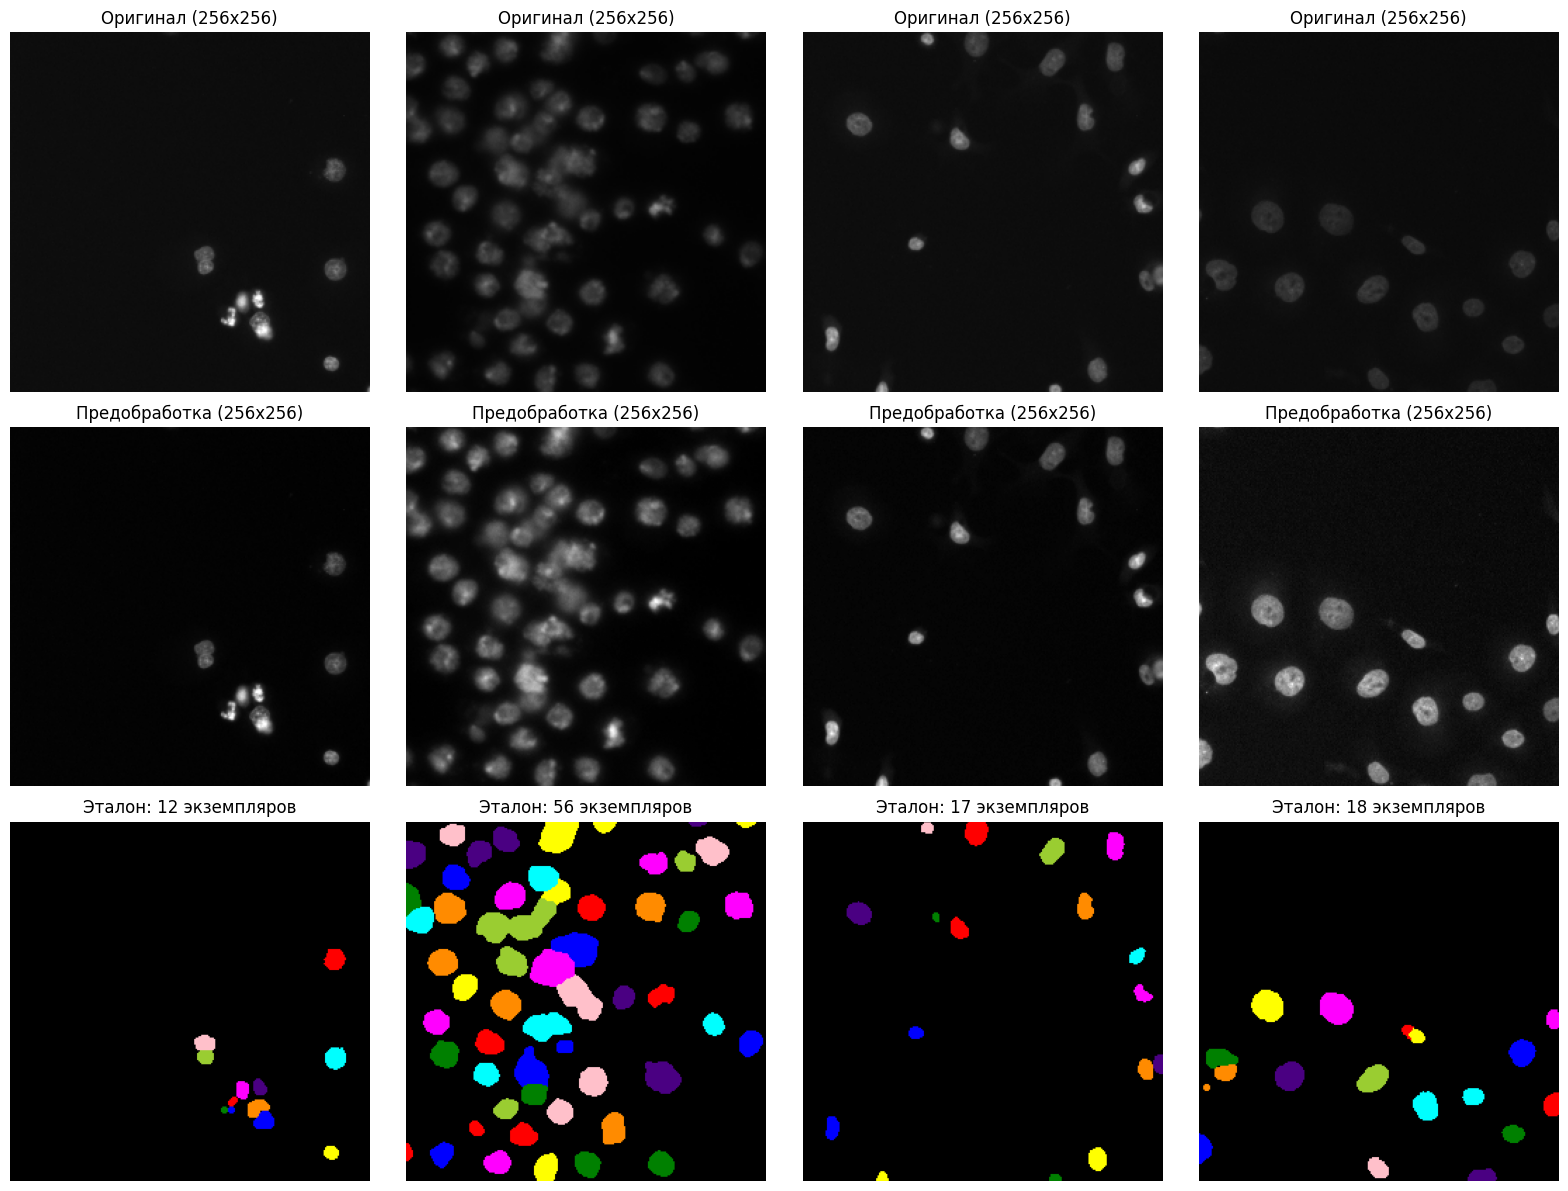

In [23]:
def show_inst(lab):
    # раскраска карты экземпляров: каждый объект - свой цвет
    return color.label2rgb(lab, bg_label=0)

examples = train_idx[:4]
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for j, i in enumerate(examples):
    axes[0, j].imshow(images_orig[i])
    axes[0, j].set_title(f"Оригинал ({images_orig[i].shape[1]}x{images_orig[i].shape[0]})")
    axes[1, j].imshow(images[i], cmap="gray")
    axes[1, j].set_title("Предобработка (256x256)")
    axes[2, j].imshow(show_inst(labels[i]))
    axes[2, j].set_title(f"Эталон: {labels[i].max()} экземпляров")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Метрики качества Instance Segmentation

Чтобы сравнивать методы, нужно сопоставить предсказанные объекты с эталонными. Для этого считаю матрицу IoU между всеми парами (эталонный объект, предсказанный объект)

- Пара считается совпадением (**TP**), если IoU > порога t. При t ≥ 0.5 каждому эталонному объекту может соответствовать не больше одного предсказания, поэтому сопоставление однозначное
- **FP** — предсказанный объект, которому не нашлось пары; **FN** — пропущенный эталонный объект
- **AP@t** = TP / (TP + FP + FN) 
- **mAP** = среднее AP@t по порогам t = 0.5, 0.55, ..., 0.95.
- Дополнительно считаю **Precision@0.5**, **Recall@0.5** и **Instance IoU** — средний IoU для каждого эталонного объекта с его лучшим предсказанием

Метрики считаю для каждого изображения и потом усредняю по тестовой выборке


In [ ]:
THRESHOLDS = np.arange(0.5, 1.0, 0.05)

def iou_matrix(gt, pred):
    # IoU между всеми парами объектов через таблицу сопряжённости
    n_gt, n_pred = gt.max(), pred.max()
    inter = np.bincount(gt.ravel() * (n_pred + 1) + pred.ravel(),
                        minlength=(n_gt + 1) * (n_pred + 1)).reshape(n_gt + 1, n_pred + 1)
    area_gt = inter.sum(axis=1, keepdims=True)
    area_pred = inter.sum(axis=0, keepdims=True)
    union = area_gt + area_pred - inter
    iou = inter / np.maximum(union, 1)
    return iou[1:, 1:]  # убираем фон


def instance_metrics(gt, pred):
    n_gt, n_pred = gt.max(), pred.max()
    if n_gt == 0 or n_pred == 0:
        zeros = {f"AP@{t:.2f}": 0.0 for t in THRESHOLDS}
        return {**zeros, "mAP": 0.0, "Precision@0.5": 0.0, "Recall@0.5": 0.0,
                "Instance IoU": 0.0, "n_gt": n_gt, "n_pred": n_pred}
    iou = iou_matrix(gt, pred)
    res = {}
    for t in THRESHOLDS:
        tp = (iou > t).sum()
        fp = n_pred - tp
        fn = n_gt - tp
        res[f"AP@{t:.2f}"] = tp / (tp + fp + fn)
    res["mAP"] = np.mean([res[f"AP@{t:.2f}"] for t in THRESHOLDS])
    tp05 = (iou > 0.5).sum()
    res["Precision@0.5"] = tp05 / n_pred
    res["Recall@0.5"] = tp05 / n_gt
    res["Instance IoU"] = iou.max(axis=1).mean()
    res["n_gt"], res["n_pred"] = n_gt, n_pred
    return res


def evaluate(preds, idx):
    all_res = [instance_metrics(labels[i], p) for i, p in zip(idx, preds)]
    keys = ["AP@0.50", "AP@0.75", "mAP", "Precision@0.5", "Recall@0.5", "Instance IoU"]
    return {k: float(np.mean([r[k] for r in all_res])) for k in keys}, all_res


# проверка: Эталон сам с собой должен давать единицы
print(instance_metrics(labels[0], labels[0])["mAP"])

1.0


## Подход 1. DBSCAN

DBSCAN — алгоритм кластеризации по плотности: точки, у которых в радиусе `eps` есть хотя бы `min_samples` соседей, объединяются в один кластер. Число кластеров заранее задавать не нужно — это удобно, потому что количество ядер на картинке заранее неизвестно. Основная идея в том, что каждый пиксель ядра — это точка, а отдельное ядро — это плотная группа таких точек. Тогда каждый кластер = отдельный экземпляр объекта.

**Алгоритм:**
1. Порогом Отсу отделяю пиксели объектов от фона
2. Если кластеризовать просто по координатам, то соприкасающиеся ядра слипнутся в один кластер, поэтому для кластеризации беру только центральные пиксели — у которых расстояние до фона не меньше `core_dist`
3. Признаки для каждого пикселя: `(x, y, w * яркость)`. Координаты отвечают за пространственную близость, а яркость (с весом `w`) помогает разделить ядра разной яркости
4. Шум (метка -1) отбрасываю
5. Отброшенные краевые пиксели возвращаю ближайшему кластеру. Маленькие ядра, у которых вообще не было центральных пикселей - отдельные объекты
6. Удаляю совсем маленькие объекты (< 10 пикселей) — это обычно шум

In [ ]:
MIN_SIZE = 10

def dbscan_segment(gray, eps=1.5, min_samples=4, w=0.0, core_dist=0):
    # 1. бинаризация по Отсу
    thr = threshold_otsu(gray)
    fg = gray > thr
    fg = remove_small(fg, MIN_SIZE)
    if fg.sum() == 0:
        return np.zeros(gray.shape, dtype=np.int32)

    # 2. оставляем только центральные пиксели объектов
    dist = ndi.distance_transform_edt(fg)
    core = dist >= core_dist if core_dist > 0 else fg

    # 3. признаки
    ys, xs = np.nonzero(core)
    feats = np.stack([xs, ys, w * gray[ys, xs] * 10], axis=1).astype(np.float32)

    # 4. кластеризация
    clusters = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(feats)
    inst = np.zeros(gray.shape, dtype=np.int32)
    inst[ys, xs] = clusters + 1  # шум (-1) превращается в 0

    # 5. возвращаем краевые пиксели ближайшему кластеру
    inst = expand_labels(inst, distance=core_dist + 2) * fg

    # маленькие ядра без центральных пикселей -> отдельные объекты
    rest = label(fg & (inst == 0), connectivity=1)
    rest[rest > 0] += inst.max()
    inst = np.where(inst == 0, rest, inst)

    # 6. убираем мелочь и перенумеровываем
    inst = remove_small(inst, MIN_SIZE)
    return relabel(inst)

### Подбор параметров DBSCAN

Параметры подбираю по сетке на валидационной выборке, критерий — mAP. Перебираю:
- `eps` — радиус соседства;
- `w` — вес яркости в признаках;
- `core_dist` — насколько сильно «обрезаем» объекты перед кластеризацией

In [8]:
param_grid = []
for core_dist in [0, 2, 3]:
    for eps in [1.5, 2.5]:
        for w in [0.0, 1.0, 3.0]:
            param_grid.append(dict(eps=eps, w=w, core_dist=core_dist))

t0 = time.time()
grid_results = []
for p in param_grid:
    preds = [dbscan_segment(images[i], **p) for i in val_idx]
    m, _ = evaluate(preds, val_idx)
    grid_results.append((p, m))
    print(f"{p}  ->  mAP={m['mAP']:.4f}  AP@0.5={m['AP@0.50']:.4f}")
print(f"Перебор занял {time.time() - t0:.1f} с")

best_params, best_m = max(grid_results, key=lambda x: x[1]["mAP"])
print("\nЛучшие параметры:", best_params, " mAP на val:", round(best_m["mAP"], 4))

{'eps': 1.5, 'w': 0.0, 'core_dist': 0}  ->  mAP=0.4033  AP@0.5=0.5804
{'eps': 1.5, 'w': 1.0, 'core_dist': 0}  ->  mAP=0.3976  AP@0.5=0.5754
{'eps': 1.5, 'w': 3.0, 'core_dist': 0}  ->  mAP=0.3296  AP@0.5=0.4830
{'eps': 2.5, 'w': 0.0, 'core_dist': 0}  ->  mAP=0.3916  AP@0.5=0.5657
{'eps': 2.5, 'w': 1.0, 'core_dist': 0}  ->  mAP=0.3915  AP@0.5=0.5667
{'eps': 2.5, 'w': 3.0, 'core_dist': 0}  ->  mAP=0.3802  AP@0.5=0.5556
{'eps': 1.5, 'w': 0.0, 'core_dist': 2}  ->  mAP=0.4099  AP@0.5=0.5889
{'eps': 1.5, 'w': 1.0, 'core_dist': 2}  ->  mAP=0.4080  AP@0.5=0.5905
{'eps': 1.5, 'w': 3.0, 'core_dist': 2}  ->  mAP=0.3495  AP@0.5=0.5123
{'eps': 2.5, 'w': 0.0, 'core_dist': 2}  ->  mAP=0.4091  AP@0.5=0.5883
{'eps': 2.5, 'w': 1.0, 'core_dist': 2}  ->  mAP=0.4095  AP@0.5=0.5896
{'eps': 2.5, 'w': 3.0, 'core_dist': 2}  ->  mAP=0.4029  AP@0.5=0.5832
{'eps': 1.5, 'w': 0.0, 'core_dist': 3}  ->  mAP=0.4183  AP@0.5=0.6058
{'eps': 1.5, 'w': 1.0, 'core_dist': 3}  ->  mAP=0.4203  AP@0.5=0.6117
{'eps': 1.5, 'w': 3.

При `core_dist = 0`, `eps = 1.5` и `w = 0` в радиус соседства попадают только 8 соседних пикселей, поэтому DBSCAN по сути ищет связные компоненты — соприкасающиеся ядра склеиваются. Отбрасывание краевых пикселей помогает: с ростом `core_dist` от 0 до 3 лучший mAP вырос с 0.403 до 0.420, а AP@0.5 — с 0.580 до 0.612. Прирост небольшой, то есть разделяется только часть слипшихся ядер.
Вес яркости `w = 1` почти не влияет на результат по сравнению с `w = 0`, а большой вес `w = 3` при малом `eps` заметно ухудшает качество (mAP падает до 0.33–0.37).
Перепады яркости внутри одного ядра начинают разбивать его на несколько кластеров или в шум


##### DBSCAN на тестовых данных:

In [24]:
t0 = time.time()
dbscan_preds = [dbscan_segment(images[i], **best_params) for i in test_idx]
print(f"DBSCAN на test: {(time.time() - t0) / len(test_idx) * 1000:.0f} мс на изображение")

dbscan_metrics, dbscan_all = evaluate(dbscan_preds, test_idx)
for k, v in dbscan_metrics.items():
    print(f"{k:15s}: {v:.4f}")

DBSCAN на test: 20 мс на изображение
AP@0.50        : 0.6082
AP@0.75        : 0.4497
mAP            : 0.4228
Precision@0.5  : 0.7352
Recall@0.5     : 0.6984
Instance IoU   : 0.6507


## Подход 2. U-Net

Обычная U-Net выдаёт семантическую маску «ядро / фон». Если просто взять связные компоненты такой маски, соприкасающиеся ядра опять склеятся. Поэтому сеть учу предсказывать **два канала**:
1. **маска объектов** — пиксель принадлежит какому-либо ядру
2. **границы объектов** — пиксели на краю каждого ядра. Особенно важны границы в местах соприкосновения ядер

**Постобработка (разделение на экземпляры):**
1. `маска > 0.5` — область всех объектов
2. `маска > 0.5` и `граница < 0.5` — «внутренности» ядер, между соседними ядрами они уже не соприкасаются. Связные компоненты внутренностей = маркеры
3. алгоритм **watershed** расширяет маркеры обратно до полной маски объекта. В итоге каждое ядро получает свой id

### Подготовка таргетов и Dataset

Для каждой картинки из карты экземпляров делаю таргеты: маску (`labels > 0`) и границы (`find_boundaries(..., mode="inner")` — граница внутри каждого объекта). В train добавляю простые аугментации: случайные отражения и повороты на 90°

targets: (670, 2, 256, 256)
Доля пикселей-объектов: 0.139, доля пикселей-границ: 0.026


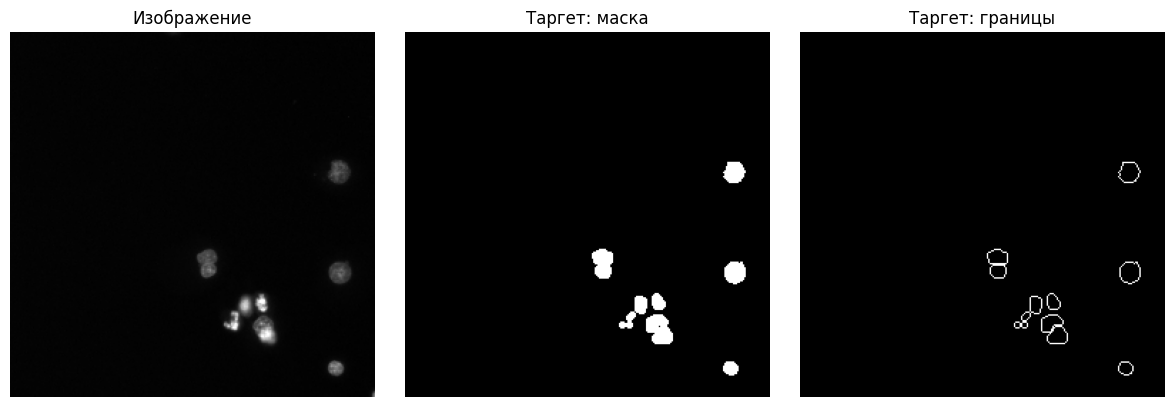

In [ ]:
def make_targets(lab):
    fg = (lab > 0).astype(np.float32)
    bnd = find_boundaries(lab, mode="inner").astype(np.float32)
    return np.stack([fg, bnd])

targets = np.stack([make_targets(lab) for lab in labels])
print("targets:", targets.shape)
print(f"Доля пикселей-объектов: {targets[:, 0].mean():.3f}, доля пикселей-границ: {targets[:, 1].mean():.3f}")


class NucleiDataset(Dataset):
    def __init__(self, idx, augment=False):
        self.idx = idx
        self.augment = augment

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, k):
        i = self.idx[k]
        x = images[i][None]
        y = targets[i] 
        if self.augment:
            if random.random() < 0.5:
                x, y = x[:, :, ::-1], y[:, :, ::-1]
            if random.random() < 0.5:
                x, y = x[:, ::-1, :], y[:, ::-1, :]
            r = random.randint(0, 3)
            x, y = np.rot90(x, r, axes=(1, 2)), np.rot90(y, r, axes=(1, 2))
        return torch.from_numpy(x.copy()), torch.from_numpy(y.copy())


g = torch.Generator()
g.manual_seed(SEED)

BATCH_SIZE = 8
train_loader = DataLoader(NucleiDataset(train_idx, augment=True), batch_size=BATCH_SIZE,
                          shuffle=True, generator=g)
val_loader = DataLoader(NucleiDataset(val_idx), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(NucleiDataset(test_idx), batch_size=BATCH_SIZE, shuffle=False)

# пример маски и границ
i = train_idx[0]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(images[i], cmap="gray"); axes[0].set_title("Изображение")
axes[1].imshow(targets[i, 0], cmap="gray"); axes[1].set_title("Таргет: маска")
axes[2].imshow(targets[i, 1], cmap="gray"); axes[2].set_title("Таргет: границы")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

### Архитектура U-Net

Классическая U-Net: энкодер (4 блока «две свёртки 3×3 + BatchNorm + ReLU», после каждого MaxPool), bottleneck и декодер с транспонированными свёртками и skip-connection'ами (конкатенация с признаками энкодера того же размера). На выходе свёртка 1×1 на 2 канала

Взял базовое число каналов 32 (32 → 64 → 128 → 256 → 512)

In [11]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=2, base=32):
        super().__init__()
        chs = [base, base * 2, base * 4, base * 8]
        self.downs = nn.ModuleList()
        prev = in_ch
        for c in chs:
            self.downs.append(DoubleConv(prev, c))
            prev = c
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(chs[-1], chs[-1] * 2)

        self.ups = nn.ModuleList()
        self.up_convs = nn.ModuleList()
        prev = chs[-1] * 2
        for c in reversed(chs):
            self.ups.append(nn.ConvTranspose2d(prev, c, 2, stride=2))
            self.up_convs.append(DoubleConv(c * 2, c))
            prev = c
        self.head = nn.Conv2d(chs[0], out_ch, 1)

    def forward(self, x):
        skips = []
        for down in self.downs:
            x = down(x)
            skips.append(x)
            x = self.pool(x)
        x = self.bottleneck(x)
        for up, conv, skip in zip(self.ups, self.up_convs, reversed(skips)):
            x = up(x)
            x = torch.cat([skip, x], dim=1)
            x = conv(x)
        return self.head(x)


model = UNet().to(device)
print("Параметров:", sum(p.numel() for p in model.parameters()))

Параметров: 7762498


### Функция потерь и обучение

Loss = BCE + Dice для каждого из двух каналов. Dice добавляю потому, что пикселей-границ мало, и на одном BCE сеть может начать предсказывать «везде нет границ»

Оптимизатор Adam (lr = 1e-3), 50 эпох, lr уменьшается по косинусу. Сохраняю веса с лучшим loss на валидации

In [12]:
def dice_loss(logits, target, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * target).sum(dim=(1, 2))
    union = p.sum(dim=(1, 2)) + target.sum(dim=(1, 2))
    return (1 - (2 * inter + eps) / (union + eps)).mean()


def criterion(logits, y):
    loss = 0
    for c in range(2):
        loss = loss + F.binary_cross_entropy_with_logits(logits[:, c], y[:, c]) + dice_loss(logits[:, c], y[:, c])
    return loss


EPOCHS = 50
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {"train": [], "val": []}
best_val = float("inf")
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(x)
    train_loss /= len(train_loader.dataset)
    scheduler.step()

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            val_loss += criterion(model(x), y).item() * len(x)
    val_loss /= len(val_loader.dataset)

    history["train"].append(train_loss)
    history["val"].append(val_loss)
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), "unet_best.pt")
    if epoch % 5 == 0 or epoch == 1:
        print(f"Эпоха {epoch:2d}: train loss={train_loss:.4f}, val loss={val_loss:.4f}")

print(f"Обучение заняло {(time.time() - t0) / 60:.1f} мин, лучший val loss = {best_val:.4f}")

Эпоха  1: train loss=2.6888, val loss=2.4548
Эпоха  5: train loss=1.1821, val loss=1.0792
Эпоха 10: train loss=0.8878, val loss=0.8841
Эпоха 15: train loss=0.8279, val loss=0.8539
Эпоха 20: train loss=0.7972, val loss=0.8388
Эпоха 25: train loss=0.7748, val loss=0.8269
Эпоха 30: train loss=0.7572, val loss=0.7912
Эпоха 35: train loss=0.7420, val loss=0.7763
Эпоха 40: train loss=0.7248, val loss=0.7847
Эпоха 45: train loss=0.7129, val loss=0.7712
Эпоха 50: train loss=0.7093, val loss=0.7664
Обучение заняло 4.7 мин, лучший val loss = 0.7638


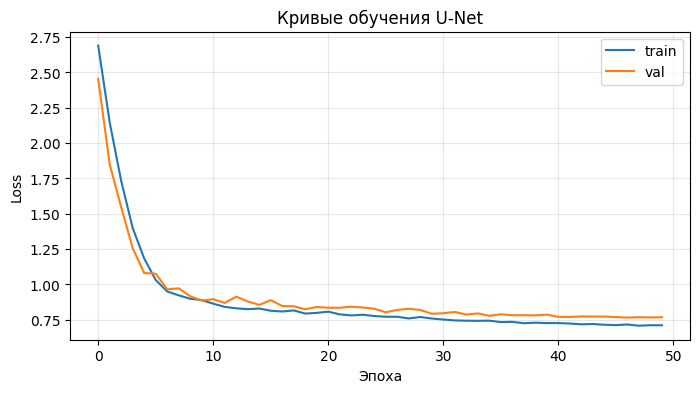

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="val")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Кривые обучения U-Net")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Комментарий по обучению:**
- Loss быстро падает в первые 10 эпох, дальше снижение идёт медленно. Так как loss — это сумма четырёх слагаемых (BCE + Dice для маски и для границ), поэтому его абсолютное значение больше 1 в начале
- Кривые train и val идут близко друг к другу: в конце обучения есть разрыв небольшой, но Val loss не начинает расти, значит сильного переобучения нет
- Лучший val loss получен в самом конце обучения, и val loss всё ещё немного снижался. Значит, можно было бы обучать сеть ещё дольше и, возможно, получить чуть лучшее качество

### Выделение экземпляров из выхода U-Net

Реализую постобработку, описанную выше: маркеры = внутренности ядер, дальше watershed по карте вероятности маски

Для сравнения также посчитаю вариант **«U-Net без границ»** — просто связные компоненты маски. Так будет видно, насколько помогает канал границ

In [ ]:
model.load_state_dict(torch.load("unet_best.pt"))
model.eval()

def predict_probs(idx):
    loader = DataLoader(NucleiDataset(idx), batch_size=BATCH_SIZE, shuffle=False)
    probs = []
    with torch.no_grad():
        for x, _ in loader:
            probs.append(torch.sigmoid(model(x.to(device))).cpu().numpy())
    return np.concatenate(probs)


def unet_postprocess(prob, fg_thr=0.5, bnd_thr=0.5):
    fg = prob[0] > fg_thr
    inner = fg & (prob[1] < bnd_thr)
    markers = label(remove_small(inner, 3), connectivity=1)
    inst = watershed(-prob[0], markers, mask=fg)
    inst = remove_small(inst, MIN_SIZE)
    return relabel(inst)


def unet_cc(prob, fg_thr=0.5):
    # вариант без разделения
    fg = remove_small(prob[0] > fg_thr, MIN_SIZE)
    return label(fg, connectivity=1)


t0 = time.time()
test_probs = predict_probs(test_idx)
unet_preds = [unet_postprocess(p) for p in test_probs]
print(f"U-Net на test: {(time.time() - t0) / len(test_idx) * 1000:.0f} мс на изображение (вместе с постобработкой)")
unet_cc_preds = [unet_cc(p) for p in test_probs]

unet_metrics, unet_all = evaluate(unet_preds, test_idx)
unet_cc_metrics, _ = evaluate(unet_cc_preds, test_idx)
for k in unet_metrics:
    print(f"{k:15s}: U-Net+границы+watershed = {unet_metrics[k]:.4f} | U-Net без границ = {unet_cc_metrics[k]:.4f}")

U-Net на test: 8 мс на изображение (вместе с постобработкой)
AP@0.50        : U-Net+границы+watershed = 0.6998 | U-Net без границ = 0.6813
AP@0.75        : U-Net+границы+watershed = 0.5477 | U-Net без границ = 0.5267
mAP            : U-Net+границы+watershed = 0.5214 | U-Net без границ = 0.5041
Precision@0.5  : U-Net+границы+watershed = 0.8255 | U-Net без границ = 0.8234
Recall@0.5     : U-Net+границы+watershed = 0.7759 | U-Net без границ = 0.7510
Instance IoU   : U-Net+границы+watershed = 0.7234 | U-Net без границ = 0.7079


## Визуализация результатов

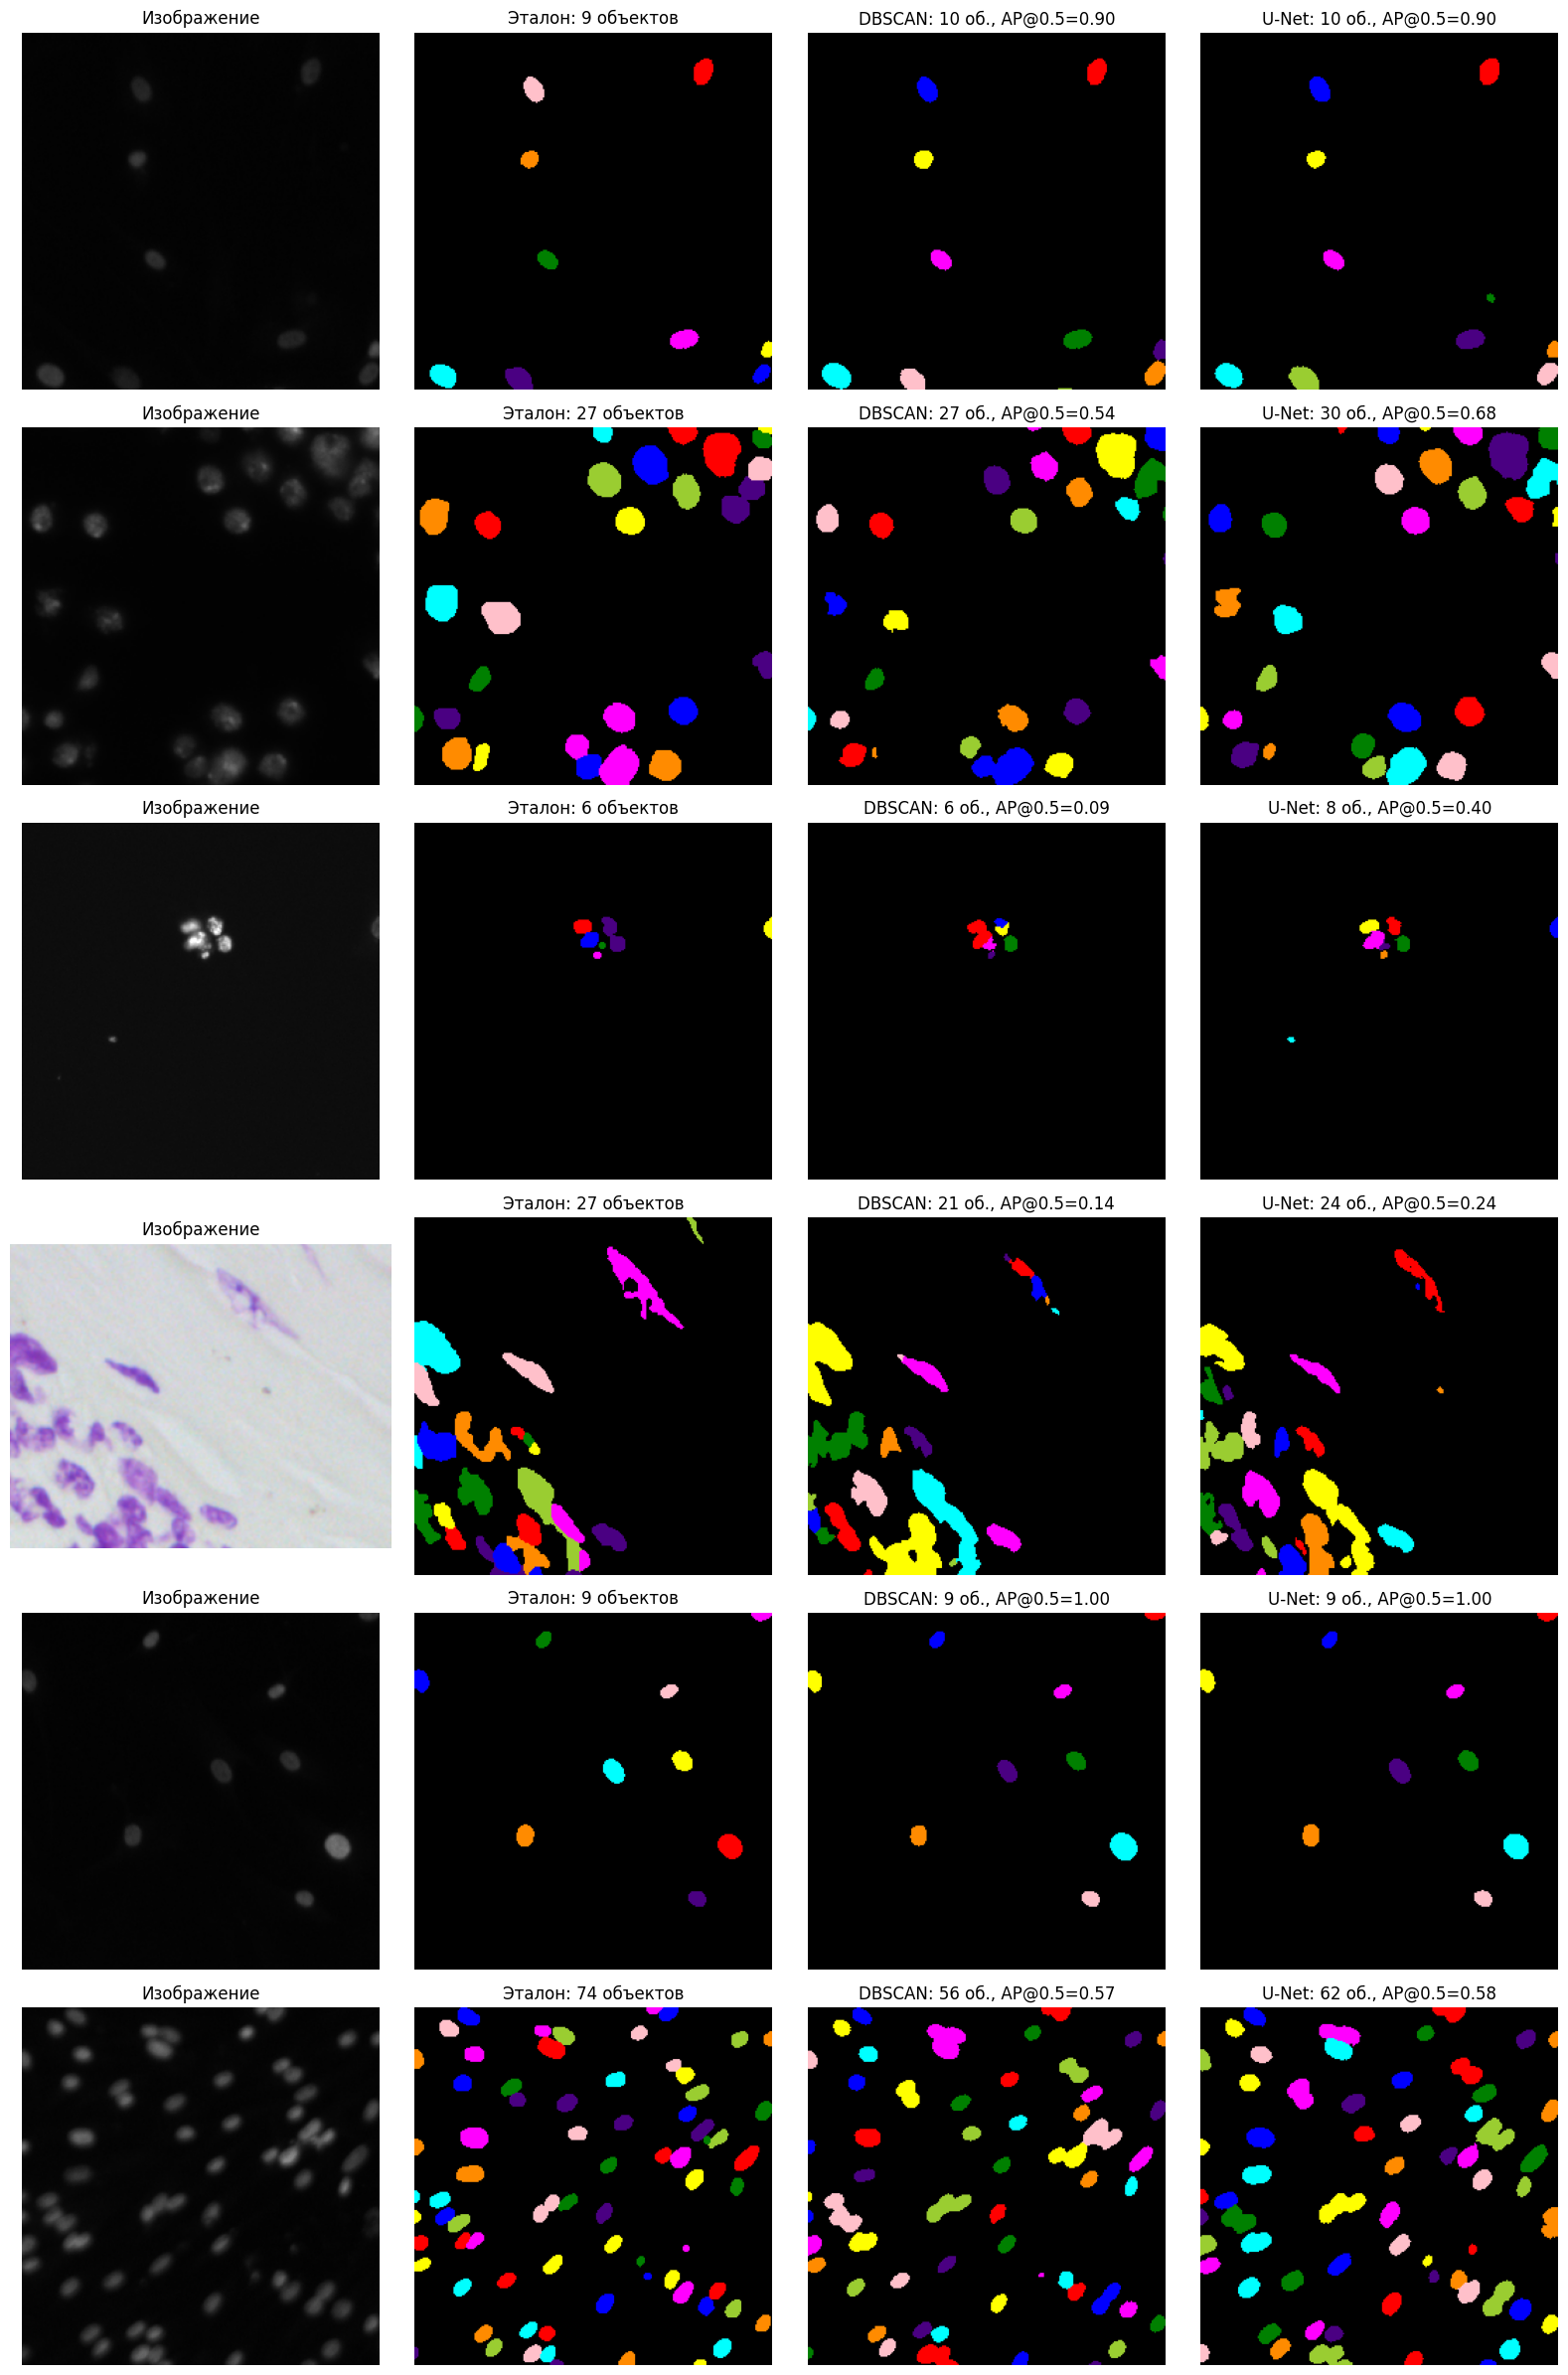

In [25]:
def plot_results(idx_list, title=None):
    fig, axes = plt.subplots(len(idx_list), 4, figsize=(16, 4 * len(idx_list)))
    for row, k in enumerate(idx_list):
        i = test_idx[k]
        d = instance_metrics(labels[i], dbscan_preds[k])
        u = instance_metrics(labels[i], unet_preds[k])
        axes[row, 0].imshow(images_orig[i])
        axes[row, 0].set_title("Изображение")
        axes[row, 1].imshow(show_inst(labels[i]))
        axes[row, 1].set_title(f"Эталон: {labels[i].max()} объектов")
        axes[row, 2].imshow(show_inst(dbscan_preds[k]))
        axes[row, 2].set_title(f"DBSCAN: {dbscan_preds[k].max()} об., AP@0.5={d['AP@0.50']:.2f}")
        axes[row, 3].imshow(show_inst(unet_preds[k]))
        axes[row, 3].set_title(f"U-Net: {unet_preds[k].max()} об., AP@0.5={u['AP@0.50']:.2f}")
    for ax in axes.flat:
        ax.axis("off")
    if title:
        fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

plot_results([0, 1, 2, 3, 4, 5])

Посмотрим поближе на кусок изображения с большим количеством соприкасающихся ядер

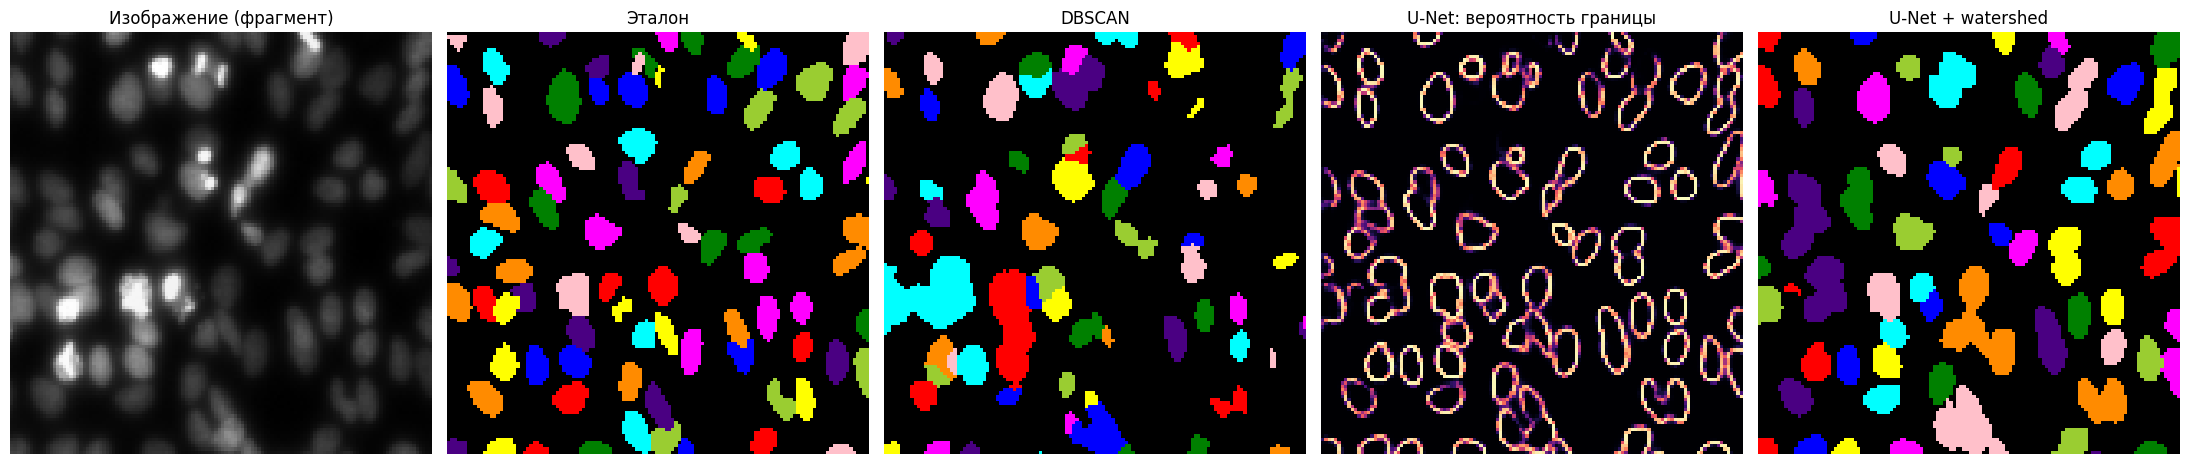

In [27]:
# берём тестовую картинку с наибольшим числом объектов
k = int(np.argmax([labels[i].max() for i in test_idx]))
i = test_idx[k]
sl = (slice(0, 128), slice(0, 128)) 

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
axes[0].imshow(images[i][sl], cmap="gray"); axes[0].set_title("Изображение (фрагмент)")
axes[1].imshow(show_inst(labels[i][sl])); axes[1].set_title("Эталон")
axes[2].imshow(show_inst(dbscan_preds[k][sl])); axes[2].set_title("DBSCAN")
axes[3].imshow(test_probs[k, 1][sl], cmap="magma"); axes[3].set_title("U-Net: вероятность границы")
axes[4].imshow(show_inst(unet_preds[k][sl])); axes[4].set_title("U-Net + watershed")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

## Сравнение методов

In [28]:
import pandas as pd

results = pd.DataFrame({
    "DBSCAN": dbscan_metrics,
    "U-Net без границ (CC)": unet_cc_metrics,
    "U-Net + границы + watershed": unet_metrics,
}).T
results.round(4)

,AP@0.50,AP@0.75,mAP,Precision@0.5,Recall@0.5,Instance IoU
DBSCAN,0.6082,0.4497,0.4228,0.7352,0.6984,0.6507
U-Net без границ (CC),0.6813,0.5267,0.5041,0.8234,0.7510,0.7079
U-Net + границы + watershed,0.6998,0.5477,0.5214,0.8255,0.7759,0.7234


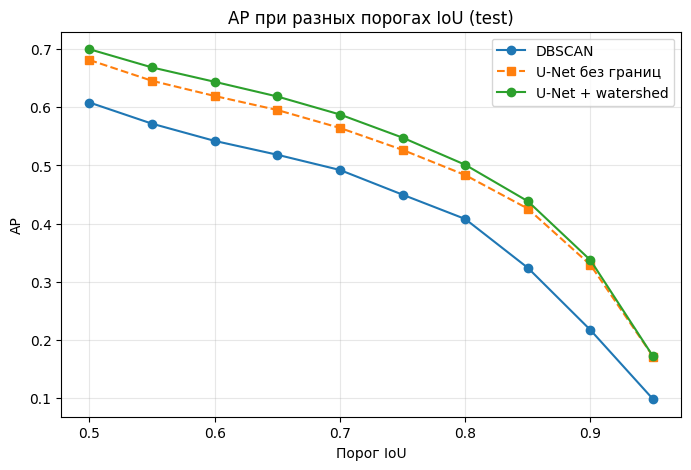

In [29]:
# AP в зависимости от порога IoU
def ap_curve(all_res):
    return [np.mean([r[f"AP@{t:.2f}"] for r in all_res]) for t in THRESHOLDS]

_, unet_cc_all = evaluate(unet_cc_preds, test_idx)

plt.figure(figsize=(8, 5))
plt.plot(THRESHOLDS, ap_curve(dbscan_all), "o-", label="DBSCAN")
plt.plot(THRESHOLDS, ap_curve(unet_cc_all), "s--", label="U-Net без границ")
plt.plot(THRESHOLDS, ap_curve(unet_all), "o-", label="U-Net + watershed")
plt.xlabel("Порог IoU")
plt.ylabel("AP")
plt.title("AP при разных порогах IoU (test)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Комментарий по сравнению:**
- U-Net с постобработкой лучше DBSCAN по всем метрикам: AP@0.5, mAP и Instance IoU, также у U-Net выше и Precision, и Recall
- На графике кривая U-Net на всех порогах IoU лежит выше кривой DBSCAN
- Вариант U-Net с границами и watershed лучше варианта без границ примерно на 0.02 при порогах 0.5–0.8, а при порогах 0.85–0.95 кривые почти совпадают. То есть канал границ помогает правильно разделить часть соприкасающихся ядер, но на точность формы отдельных масок почти не влияет
- У всех методов AP резко падает после порога 0.8. Ядра маленькие (особенно после уменьшения до 256×256), и ошибка всего в 1–2 пикселя по краю заметно снижает IoU, поэтому совпадение с IoU > 0.9 получить сложно
- По скорости DBSCAN работает около 20 мс на изображение, U-Net вместе с постобработкой — около 8 мс на GPU (без учёта времени на обучение сети)

### Сравнение по типам изображений

В датасете есть два сильно разных типа снимков, посмотрим, как методы работают на каждом из них

In [19]:
test_bright = bright[test_idx]
rows = []
for name, all_res in [("DBSCAN", dbscan_all), ("U-Net + watershed", unet_all)]:
    for group, mask in [("тёмный фон", ~test_bright), ("светлый фон", test_bright)]:
        sel = [r for r, m in zip(all_res, mask) if m]
        rows.append({"Метод": name, "Тип": group, "Кол-во изображений": len(sel),
                     "AP@0.5": np.mean([r["AP@0.50"] for r in sel]),
                     "mAP": np.mean([r["mAP"] for r in sel])})
pd.DataFrame(rows).round(4)

,Метод,Тип,Кол-во изображений,AP@0.5,mAP
0,DBSCAN,тёмный фон,82,0.6736,0.4809
1,DBSCAN,светлый фон,20,0.3398,0.1848
2,U-Net + watershed,тёмный фон,82,0.7520,0.5807
3,U-Net + watershed,светлый фон,20,0.4861,0.2780


## Анализ типичных ошибок

Посчитаю, какие ошибки делает каждый метод:
- **слияние (merge)** — один предсказанный объект накрывает 2 и более Эталон-ядра (каждое Эталон-ядро покрыто им больше чем наполовину)
- **разбиение (split)** — одно Эталон-ядро разбито на 2 и более предсказанных объекта (каждый кусок больше чем наполовину лежит внутри этого ядра)
- **пропуски (FN)** и **ложные срабатывания (FP)** при IoU > 0.5

In [30]:
def error_stats(gt, pred):
    n_gt, n_pred = gt.max(), pred.max()
    if n_gt == 0 or n_pred == 0:
        return dict(merge=0, split=0, FN=n_gt, FP=n_pred)
    inter = np.bincount(gt.ravel() * (n_pred + 1) + pred.ravel(),
                        minlength=(n_gt + 1) * (n_pred + 1)).reshape(n_gt + 1, n_pred + 1)
    area_gt = inter.sum(axis=1)[1:]
    area_pred = inter.sum(axis=0)[1:]
    inter = inter[1:, 1:]
    
    cover_gt = inter / np.maximum(area_gt[:, None], 1)
    cover_pred = inter / np.maximum(area_pred[None, :], 1)
    merge = ((cover_gt > 0.5).sum(axis=0) >= 2).sum()
    split = ((cover_pred > 0.5).sum(axis=1) >= 2).sum()
    tp = (iou_matrix(gt, pred) > 0.5).sum()
    return dict(merge=merge, split=split, FN=n_gt - tp, FP=n_pred - tp)


rows = []
for name, preds in [("DBSCAN", dbscan_preds), ("U-Net + watershed", unet_preds)]:
    s = [error_stats(labels[i], p) for i, p in zip(test_idx, preds)]
    rows.append({"Метод": name,
                 "GT объектов": int(sum(labels[i].max() for i in test_idx)),
                 "Найдено объектов": int(sum(p.max() for p in preds)),
                 **{k: int(sum(x[k] for x in s)) for k in ["merge", "split", "FN", "FP"]}})
errors = pd.DataFrame(rows)
errors

,Метод,GT объектов,Найдено объектов,merge,split,FN,FP
0,DBSCAN,4027,3443,361,136,1699,1115
1,U-Net + watershed,4027,3609,354,81,1277,859


Посмотрим на худшие для DBSCAN тестовые изображения

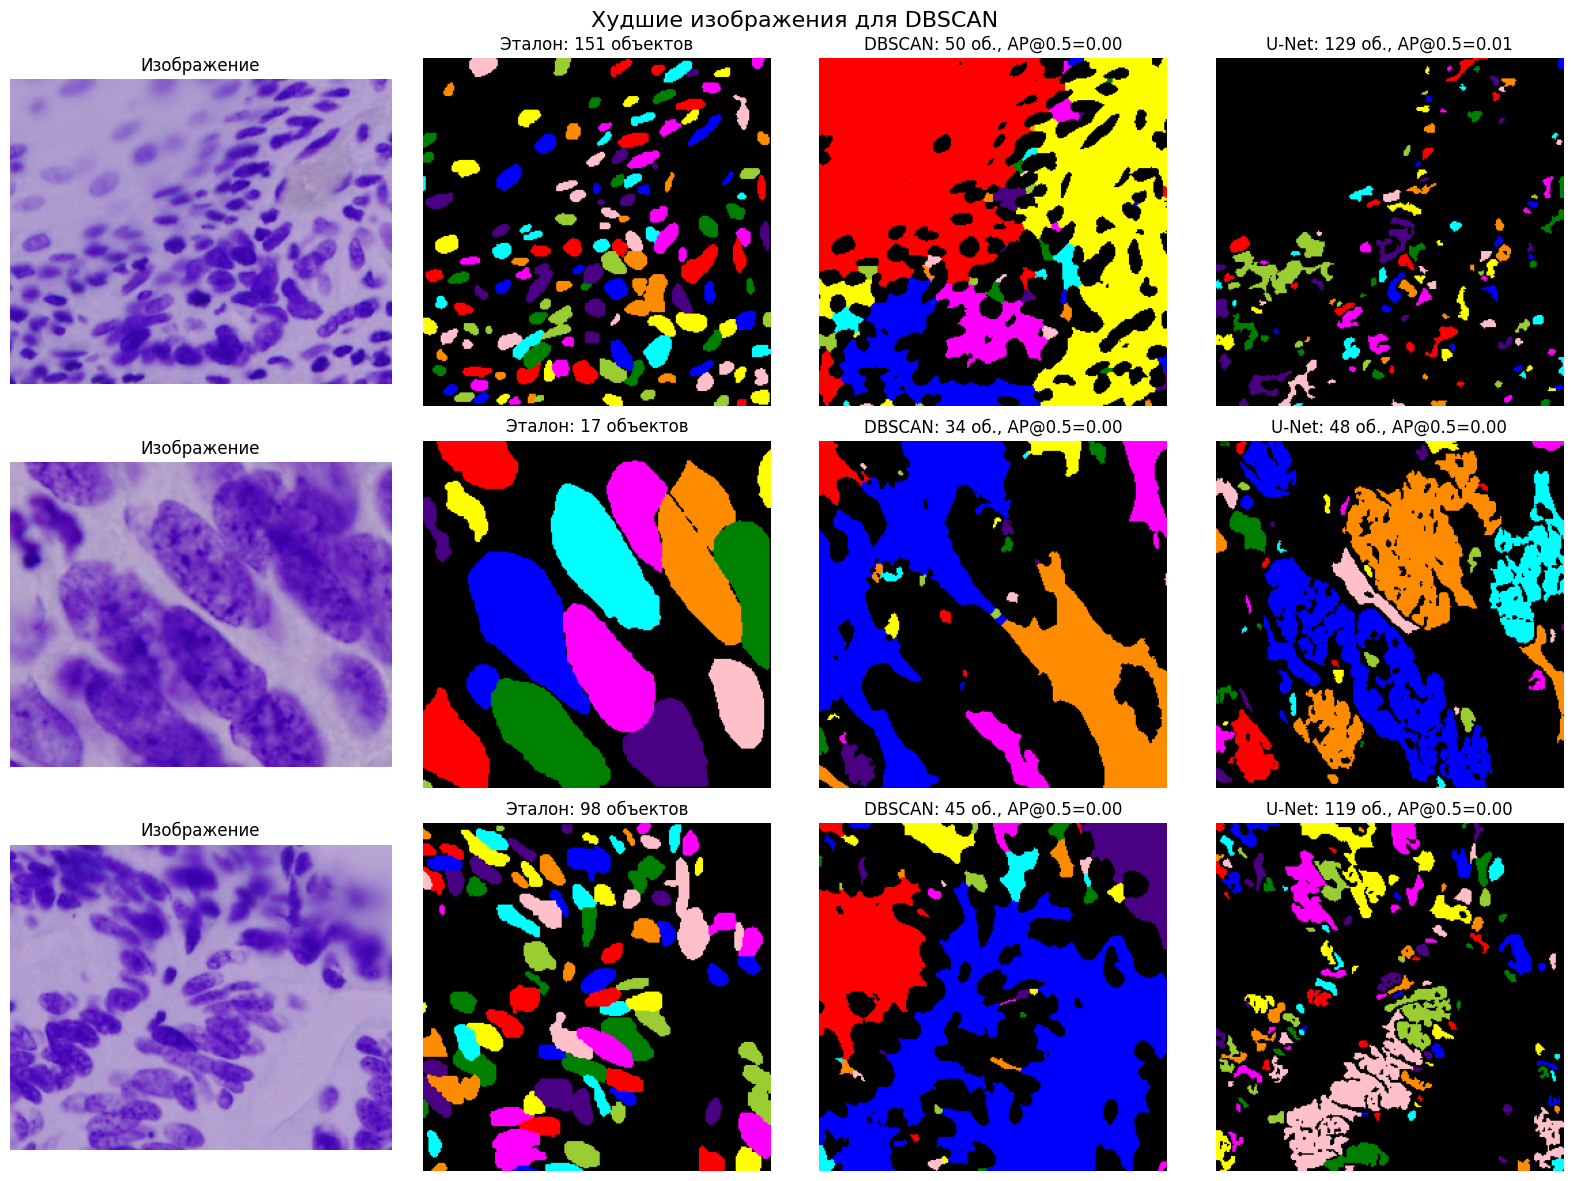

In [31]:
dbscan_ap = np.array([r["AP@0.50"] for r in dbscan_all])
worst = list(np.argsort(dbscan_ap)[:3])
plot_results(worst, title="Худшие изображения для DBSCAN")

Посмотрим на худшие для U-Net тестовые изображения

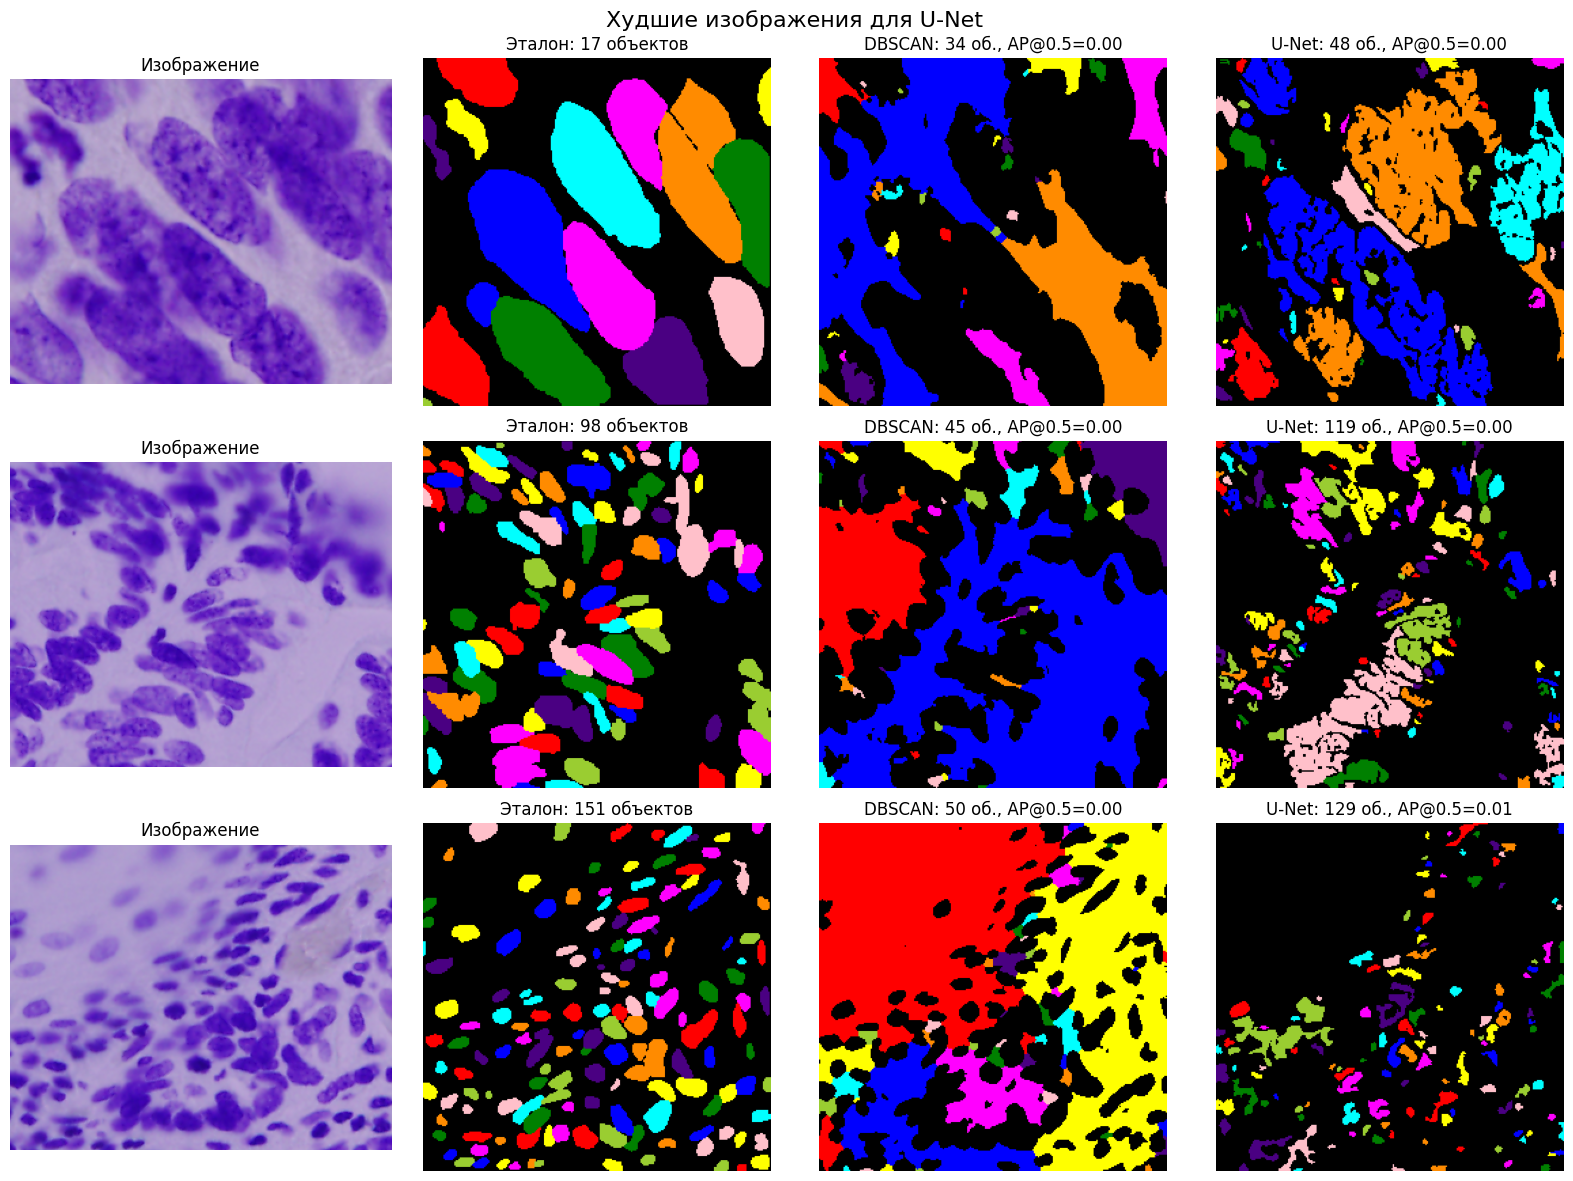

In [32]:
unet_ap = np.array([r["AP@0.50"] for r in unet_all])
worst = list(np.argsort(unet_ap)[:3])
plot_results(worst, title="Худшие изображения для U-Net")

## Выводы

1. **Оба подхода дают именно instance-сегментацию**: на выходе карта, где у каждого найденного ядра свой номер (на визуализациях соседние ядра раскрашены разными цветами)

2. **Итоговое сравнение на тестовой выборке:**

| Метод | AP@0.5 | AP@0.75 | mAP | Instance IoU |
|---|---|---|---|---|
| DBSCAN | 0.608 | 0.450 | 0.423 | 0.651 |
| U-Net без границ | 0.681 | 0.527 | 0.504 | 0.708 |
| U-Net + границы + watershed | **0.700** | **0.548** | **0.521** | **0.723** |

U-Net с постобработкой лучше DBSCAN по всем метрикам, примерно на 0.1 по mAP. При строгих порогах IoU отставание DBSCAN растёт, то есть маски DBSCAN менее точные по форме

3. **DBSCAN.**
   - При кластеризации всех пикселей объекта DBSCAN по сути ищет связные компоненты и склеивает соприкасающиеся ядра. Отбрасывание краевых пикселей помогло, но немного: mAP на валидации вырос с 0.403 до 0.420
   - Небольшой вес яркости (`w = 1`) почти не влияет на результат, а большой (`w = 3`) ухудшает качество
   - Самая частая ошибка DBSCAN — **пропуски ядер** и **ложные объекты** (FP = 1115): порог Отсу плохо отделяет тусклые ядра и неоднородный фон
   - На снимках со светлым фоном DBSCAN работает очень плохо: AP@0.5 = 0.340 против 0.674 на флуоресцентных снимках

4. **U-Net.** Сеть учится на разметке и лучше отделяет ядра от фона: по сравнению с DBSCAN меньше пропускови ложных объектов
   - Канал границ + watershed даёт небольшой, но стабильный прирост относительно простых связных компонент маски (mAP 0.521 против 0.504, Recall@0.5 0.776 против 0.751)
   - При этом число слияний у U-Net почти такое же, как у DBSCAN (354 против 361). То есть плотно прижатые ядра сеть разделяет всё ещё плохо — граница между ними на изображении 256×256 часто занимает 1–2 пикселя, и сеть её не находит. Основной выигрыш U-Net — за счёт более точной маски объектов, а не за счёт разделения экземпляров
   - На снимках со светлым фоном U-Net тоже заметно хуже (AP@0.5 = 0.486 против 0.752), но всё равно лучше DBSCAN

5. **Худшие изображения у обоих методов одни и те же** — фиолетовые снимки с крупными, плотно прижатыми ядрами

6. **Общий вывод.** U-Net с предсказанием границ и watershed — лучший из рассмотренных подходов. DBSCAN не требует разметки и обучения и легко интерпретируется, поэтому как простой baseline он работает приемлемо на однородных флуоресцентных снимках, но на сложных изображениях сильно проигрывает. Разделение соприкасающихся объектов остаётся главной нерешённой проблемой для обоих методов